<a href="https://colab.research.google.com/github/gabrielribas18/analise-custos-frete/blob/main/analise/trabalho_agraria%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:


#inportaçao da bibliotecas
import pandas as pd
import numpy as np


In [2]:
from google.colab import drive
import pandas as pd
from google.colab import auth
import gspread
from google.auth import default

# 1. Monta o Google Drive no Colab
drive.mount('/content/drive')

# Autenticação para ler o Google Sheets (.gsheet)
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

NOME_DA_PASTA = 'trabalho minoro/dados_t1/'
base_path = f'/content/drive/MyDrive/{NOME_DA_PASTA}'

# 2. Leitura do Google Sheets base_modelagem_frete
print("Carregando base_modelagem_frete.gsheet a partir do Google Sheets...")
try:
    # Abre a planilha pelo nome
    planilha = gc.open("base_modelagem_frete")
    aba = planilha.sheet1
    dados_sheet = aba.get_all_records()
    df_modelagem = pd.DataFrame(dados_sheet)
except Exception as e:
    print(f"Não foi possível ler como Google Sheets: {e}")
    print("Tentando ler como arquivo CSV tradicional...")
    caminho_base_csv = base_path + 'base_modelagem_frete.csv'
    df_modelagem = pd.read_csv(caminho_base_csv, sep=";", decimal=",")

# 3. Leitura da base de Realizados (Realizado.xlsx)
print("Carregando Realizado.xlsx (aba Data)...")
caminho_realizado = base_path + 'Realizado.xlsx'
df_realizado = pd.read_excel(caminho_realizado, sheet_name='Data')

# 4. Leitura do arquivo de Orçamento (Orcado.xlsx)
print("Carregando Orcado.xlsx (abas Orçado 26 e BPC 26)...")
caminho_orcado = base_path + 'Orcado.xlsx'
df_orcado_26 = pd.read_excel(caminho_orcado, sheet_name='Orçado 26')
df_bpc_26 = pd.read_excel(caminho_orcado, sheet_name='BPC 26')

print("\n--- Carregamento Concluído com Sucesso! ---")
print(f"Base Modelagem: {df_modelagem.shape[0]} linhas × {df_modelagem.shape[1]} colunas")
print(f"Realizado (Data):      {df_realizado.shape[0]} linhas × {df_realizado.shape[1]} colunas")
print(f"Orçado 26:             {df_orcado_26.shape[0]} linhas × {df_orcado_26.shape[1]} colunas")
print(f"BPC 26:                {df_bpc_26.shape[0]} linhas × {df_bpc_26.shape[1]} colunas")

Mounted at /content/drive
Carregando base_modelagem_frete.gsheet a partir do Google Sheets...
Carregando Realizado.xlsx (aba Data)...
Carregando Orcado.xlsx (abas Orçado 26 e BPC 26)...

--- Carregamento Concluído com Sucesso! ---
Base Modelagem: 29860 linhas × 46 colunas
Realizado (Data):      49051 linhas × 37 colunas
Orçado 26:             360 linhas × 10 colunas
BPC 26:                198 linhas × 23 colunas


In [3]:
import os

def buscar_arquivos(diretorio, termos):
    print(f"Buscando arquivos e pastas contendo {termos} no seu Drive...\n")
    encontrados = []
    for raiz, pastas, arquivos in os.walk(diretorio):
        # Evita buscar em pastas ocultas
        pastas[:] = [p for p in pastas if not p.startswith('.')]

        for nome in pastas + arquivos:
            if any(termo.lower() in nome.lower() for termo in termos):
                caminho_completo = os.path.join(raiz, nome)
                encontrados.append(caminho_completo)
                print(f"Encontrado: {caminho_completo}")

    if not encontrados:
        print("Nenhum arquivo ou pasta correspondente foi localizado no seu Drive.")

# Executa a busca na raiz do seu Google Drive
buscar_arquivos('/content/drive/MyDrive', ['minoro', 'dados', 'frete', 'Orcado', 'Realizado'])

Buscando arquivos e pastas contendo ['minoro', 'dados', 'frete', 'Orcado', 'Realizado'] no seu Drive...

Encontrado: /content/drive/MyDrive/trabalho minoro
Encontrado: /content/drive/MyDrive/Pre-Processamento-de-Dados-no-KDD-Uma-Abordagem-Pratica-para-Agronegocio.pptx (1).gdoc
Encontrado: /content/drive/MyDrive/trabalho minoro/dados_t1
Encontrado: /content/drive/MyDrive/trabalho minoro/dados_t1/Relatorio_Previsao_Custo_Frete.gdoc
Encontrado: /content/drive/MyDrive/trabalho minoro/dados_t1/base_modelagem_frete.gsheet
Encontrado: /content/drive/MyDrive/trabalho minoro/dados_t1/Realizado.xlsx
Encontrado: /content/drive/MyDrive/trabalho minoro/dados_t1/Orcado.xlsx


In [4]:
#chamando a base de dados para comesar a linpesa

#dados_1= pd.read_csv("/content/drive/MyDrive/dados_t1/base_modelagem_frete.csv")
#dados_2= pd.read_excel("/content/drive/MyDrive/Orcado.xlsx")
#dados_3= pd.read_excel("/content/drive/MyDrive/Realizado.xlsx")
''''
ja cahmeis as tres tabelas para facilitar na hora de carregar a celula
seendo a 1= modelagem
seendo a 2= orçado
seendo a 3= realisado
'''


"'\nja cahmeis as tres tabelas para facilitar na hora de carregar a celula\nseendo a 1= modelagem\nseendo a 2= orçado\nseendo a 3= realisado\n"

In [5]:
df_modelagem.head()#visualisando a primeira tabela

,Nº frete,Item,Dta.liq.,ano,mes,trimestre,dia_semana,Representante,nome_representante,destino_frete,...,share_peso_item_no_frete,tarifa_orcada_rs_t,volume_orcado_mes_t,tarifa_orcada_media_rep_rs_t,Valor líquido,frete_rs_t,flag_valor_zero,flag_rateio_divergente,flag_ctgi_nao_padrao,flag_outlier_rs_t
0,577117,3,2025-01-02,2025,1,1,3,1015075,GENARI REPRESENTACAO COMERCIAL LTDA,Palmeira,...,1,24734783078599497,1007076,18476189785670942,173745,78975,0,1,1,1
1,579605,15,2025-01-02,2025,1,1,3,1081824,REPRESENTACAO COMERCIAL AGRONUTRI E,Guarapuava,...,1,2632240084003128,46986239999999995,15113704890569628,541574,98468,0,0,1,1
2,584404,17,2025-01-02,2025,1,1,3,1119741,J V PEC REPRESENTACOES LTDA,NAO_INFORMADO,...,1,,10013759999999999,,541574,21663,0,0,1,1
3,585651,13,2025-01-02,2025,1,1,3,1081824,REPRESENTACAO COMERCIAL AGRONUTRI E,Guarapuava,...,1,2632240084003128,46986239999999995,15113704890569628,541574,676967,0,0,1,1
4,586060,16,2025-01-02,2025,1,1,3,1119741,J V PEC REPRESENTACOES LTDA,NAO_INFORMADO,...,1,,10013759999999999,,541574,722099,0,0,1,1


In [6]:
df_orcado_26.head()#visualisando a segunda tabela (Orçado 26)

,mês,Unnamed: 1,Desc,Centro de custo,Parceiro de Negócio,Desc3,Unidade medida bás,FRETE,VOLUME,R$/ton
0,JAN,1,PO Padrão Ind.Nut.An,103010,1014939,G ROSSI REPRESENTACAO COMERCIAL LTD,TO,133268.805681,642.0480,207.568290
1,JAN,1,PO Padrão Ind.Nut.An,103010,1015075,GENARI REPRESENTACAO COMERCIAL LTDA,SAC,24909.806404,100.7076,247.347831
2,JAN,1,PO Padrão Ind.Nut.An,103010,1015075,GENARI REPRESENTACAO COMERCIAL LTDA,TO,423042.384855,2323.7760,182.049554
3,JAN,1,PO Padrão Ind.Nut.An,103010,1030351,HERBI PASTO COM E REP COM DE PROD A,SAC,549.700416,2.5536,215.264887
4,JAN,1,PO Padrão Ind.Nut.An,103010,1030351,HERBI PASTO COM E REP COM DE PROD A,TO,87123.055080,313.9560,277.500844


In [7]:
df_realizado.head()#visualisando a terceira tabela (Realizado)

,LOrT,Nº frete,Item,CtgI,Valor líquido,Montante do imposto,Moeda,Dta.liq.,C,ClAv.,...,Peso líq.acumul.,Un..1,Peso bruto,Un..2,Un..3,Peso brt.acumulado,Valor líquido.1,Moeda.1,Fornecimento,Representante
0,120,436681,2,Z101,1184.30,-120.71,BRL,2025-01-20,K,3201,...,6020.0,KG,0.0,KG,KG,6020.00,591.16,BRL,81132118,1036220
1,120,436681,2,Z101,1184.30,-120.71,BRL,2025-01-20,K,3201,...,6040.0,KG,0.0,KG,KG,6040.00,593.14,BRL,81132117,1036220
2,120,438031,1,Z101,1471.04,-149.95,BRL,2025-01-21,K,3201,...,14980.0,KG,0.0,KG,KG,14980.00,1471.04,BRL,81136027,1036220
3,120,496548,2,Z101,1067.88,-108.85,BRL,2025-02-27,K,3201,...,6020.0,KG,0.0,KG,KG,6020.00,1067.88,BRL,81308457,1015075
4,120,498766,1,Z101,356.90,-90.01,BRL,2025-02-06,K,3201,...,90.0,KG,0.0,KG,KG,90.15,62.36,BRL,81308439,1015075


In [8]:
df_modelagem.shape

(29860, 46)

In [9]:
df_orcado_26.shape

(360, 10)

In [10]:
df_realizado.shape

(49051, 37)

In [11]:
df_modelagem.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29860 entries, 0 to 29859
Data columns (total 46 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   Nº frete                      29860 non-null  int64 
 1   Item                          29860 non-null  int64 
 2   Dta.liq.                      29860 non-null  object
 3   ano                           29860 non-null  int64 
 4   mes                           29860 non-null  int64 
 5   trimestre                     29860 non-null  int64 
 6   dia_semana                    29860 non-null  int64 
 7   Representante                 29860 non-null  int64 
 8   nome_representante            29860 non-null  object
 9   destino_frete                 29860 non-null  object
 10  CtgI                          29860 non-null  object
 11  T                             29860 non-null  object
 12  C.1                           29860 non-null  object
 13  TpRem           

In [12]:
df_orcado_26.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   mês                  360 non-null    object 
 1   Unnamed: 1           360 non-null    int64  
 2   Desc                 360 non-null    object 
 3   Centro de custo      360 non-null    int64  
 4   Parceiro de Negócio  360 non-null    object 
 5   Desc3                360 non-null    object 
 6   Unidade medida bás   360 non-null    object 
 7   FRETE                276 non-null    float64
 8   VOLUME               360 non-null    float64
 9   R$/ton               360 non-null    float64
dtypes: float64(3), int64(2), object(5)
memory usage: 28.3+ KB


In [13]:
df_realizado.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49051 entries, 0 to 49050
Data columns (total 37 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   LOrT                 49051 non-null  int64         
 1   Nº frete             49051 non-null  int64         
 2   Item                 49051 non-null  int64         
 3   CtgI                 49051 non-null  object        
 4   Valor líquido        49051 non-null  float64       
 5   Montante do imposto  49051 non-null  float64       
 6   Moeda                49051 non-null  object        
 7   Dta.liq.             49051 non-null  datetime64[ns]
 8   C                    49051 non-null  object        
 9   ClAv.                49051 non-null  int64         
 10  C.1                  49051 non-null  object        
 11  T                    49051 non-null  object        
 12  Cta.Razão            49051 non-null  int64         
 13  Div                  49051 non-

In [14]:
df_modelagem.columns

Index(['Nº frete', 'Item', 'Dta.liq.', 'ano', 'mes', 'trimestre', 'dia_semana',
       'Representante', 'nome_representante', 'destino_frete', 'CtgI', 'T',
       'C.1', 'TpRem', 'qtd_tprem_distintos', 'tipo_carga',
       'material_principal', 'denominacao_principal', 'n_linhas',
       'n_materiais', 'n_fornecimentos', 'n_doc_venda', 'peso_liquido_kg',
       'peso_bruto_kg', 'peso_liquido_t', 'peso_kg_um_kg', 'peso_kg_um_sac',
       'peso_kg_um_fd', 'pct_peso_um_kg', 'pct_peso_um_sac', 'pct_peso_um_fd',
       'pct_peso_pel', 'pct_peso_far', 'pct_peso_trit', 'qtd_itens_no_frete',
       'peso_total_frete_t', 'share_peso_item_no_frete', 'tarifa_orcada_rs_t',
       'volume_orcado_mes_t', 'tarifa_orcada_media_rep_rs_t', 'Valor líquido',
       'frete_rs_t', 'flag_valor_zero', 'flag_rateio_divergente',
       'flag_ctgi_nao_padrao', 'flag_outlier_rs_t'],
      dtype='object')

In [15]:
df_orcado_26.columns

Index(['mês', 'Unnamed: 1', 'Desc', 'Centro de custo', 'Parceiro de Negócio',
       'Desc3', 'Unidade medida bás', 'FRETE', 'VOLUME', 'R$/ton'],
      dtype='object')

In [16]:
df_realizado.columns

Index(['LOrT', 'Nº frete', 'Item', 'CtgI', 'Valor líquido',
       'Montante do imposto', 'Moeda', 'Dta.liq.', 'C', 'ClAv.', 'C.1', 'T',
       'Cta.Razão', 'Div', 'Centro cst', 'Doc.venda', 'TpRem', 'Itm',
       'Doc.fatur.', 'Material', 'Denominação', 'UM', 'Qtd.remessa',
       'Qtd.lote acumul.', 'UMB', 'Peso líquido', 'Un.', 'Peso líq.acumul.',
       'Un..1', 'Peso bruto', 'Un..2', 'Un..3', 'Peso brt.acumulado',
       'Valor líquido.1', 'Moeda.1', 'Fornecimento', 'Representante'],
      dtype='object')

In [17]:
df_modelagem.isna()

,Nº frete,Item,Dta.liq.,ano,mes,trimestre,dia_semana,Representante,nome_representante,destino_frete,...,share_peso_item_no_frete,tarifa_orcada_rs_t,volume_orcado_mes_t,tarifa_orcada_media_rep_rs_t,Valor líquido,frete_rs_t,flag_valor_zero,flag_rateio_divergente,flag_ctgi_nao_padrao,flag_outlier_rs_t
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29855,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
29856,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
29857,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
29858,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [18]:
df_orcado_26.isna()

,mês,Unnamed: 1,Desc,Centro de custo,Parceiro de Negócio,Desc3,Unidade medida bás,FRETE,VOLUME,R$/ton
0,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...
355,False,False,False,False,False,False,False,True,False,False
356,False,False,False,False,False,False,False,True,False,False
357,False,False,False,False,False,False,False,True,False,False
358,False,False,False,False,False,False,False,True,False,False


In [19]:
df_realizado.isna()

,LOrT,Nº frete,Item,CtgI,Valor líquido,Montante do imposto,Moeda,Dta.liq.,C,ClAv.,...,Peso líq.acumul.,Un..1,Peso bruto,Un..2,Un..3,Peso brt.acumulado,Valor líquido.1,Moeda.1,Fornecimento,Representante
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49046,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
49047,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
49048,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
49049,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


aqui usei gemini para juntar as tres tabelas em  uma so e para corigir letras e sinbolos

In [20]:
# 1. Usar a base de modelagem já carregada diretamente do Sheets
dados_1_corrigido = df_modelagem.copy()

# 2. Unir Realizado (df_realizado) com a Modelagem (dados_1_corrigido) usando as chaves do Frete
df_consolidado = pd.merge(
    df_realizado,
    dados_1_corrigido,
    on=['Nº frete', 'Item'],
    how='left',
    suffixes=('', '_modelagem')
)

# 3. Preparar as colunas de chave para unir com o Orçado (df_orcado_26)
df_consolidado['Representante'] = df_consolidado['Representante'].astype(float).fillna(0).astype(int)
df_consolidado['Centro cst'] = df_consolidado['Centro cst'].astype(float).fillna(0).astype(int)

dados_2_temp = df_orcado_26.copy()
dados_2_temp['Parceiro de Negócio'] = pd.to_numeric(dados_2_temp['Parceiro de Negócio'], errors='coerce').fillna(0).astype(int)
dados_2_temp['Centro de custo'] = dados_2_temp['Centro de custo'].astype(int)

# 4. Unir o resultado anterior com o Orçado (df_orcado_26)
df_final = pd.merge(
    df_consolidado,
    dados_2_temp,
    left_on=['Centro cst', 'Representante'],
    right_on=['Centro de custo', 'Parceiro de Negócio'],
    how='left',
    suffixes=('', '_orcado')
)

# Visualizar o resultado final consolidado
display(df_final.head())

,LOrT,Nº frete,Item,CtgI,Valor líquido,Montante do imposto,Moeda,Dta.liq.,C,ClAv.,...,mês,Unnamed: 1,Desc,Centro de custo,Parceiro de Negócio,Desc3,Unidade medida bás,FRETE,VOLUME,R$/ton
0,120,436681,2,Z101,1184.30,-120.71,BRL,2025-01-20,K,3201,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,120,436681,2,Z101,1184.30,-120.71,BRL,2025-01-20,K,3201,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,120,438031,1,Z101,1471.04,-149.95,BRL,2025-01-21,K,3201,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,120,496548,2,Z101,1067.88,-108.85,BRL,2025-02-27,K,3201,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,120,498766,1,Z101,356.90,-90.01,BRL,2025-02-06,K,3201,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
df_final.columns

Index(['LOrT', 'Nº frete', 'Item', 'CtgI', 'Valor líquido',
       'Montante do imposto', 'Moeda', 'Dta.liq.', 'C', 'ClAv.', 'C.1', 'T',
       'Cta.Razão', 'Div', 'Centro cst', 'Doc.venda', 'TpRem', 'Itm',
       'Doc.fatur.', 'Material', 'Denominação', 'UM', 'Qtd.remessa',
       'Qtd.lote acumul.', 'UMB', 'Peso líquido', 'Un.', 'Peso líq.acumul.',
       'Un..1', 'Peso bruto', 'Un..2', 'Un..3', 'Peso brt.acumulado',
       'Valor líquido.1', 'Moeda.1', 'Fornecimento', 'Representante',
       'Dta.liq._modelagem', 'ano', 'mes', 'trimestre', 'dia_semana',
       'Representante_modelagem', 'nome_representante', 'destino_frete',
       'CtgI_modelagem', 'T_modelagem', 'C.1_modelagem', 'TpRem_modelagem',
       'qtd_tprem_distintos', 'tipo_carga', 'material_principal',
       'denominacao_principal', 'n_linhas', 'n_materiais', 'n_fornecimentos',
       'n_doc_venda', 'peso_liquido_kg', 'peso_bruto_kg', 'peso_liquido_t',
       'peso_kg_um_kg', 'peso_kg_um_sac', 'peso_kg_um_fd', 'pct_peso

In [22]:
#aqui to divideindo em X=pergunytas y=respostas para que ele responda futuramente
X = [
    'Peso líquido', 'Peso bruto', 'Qtd.remessa', 'Representante',
    'Centro cst', 'CtgI', 'TpRem', 'ano', 'mes', 'dia_semana'
]
y = 'Valor líquido'

In [23]:
#aque estou fasendo uma copia somente com x e y
df_modelo = df_final[X + [y]].copy()

In [24]:
#tratamento dos dados para tirar dados nulos e invalidos
df_modelo['Peso líquido'] = df_modelo['Peso líquido'].fillna(0)
df_modelo['Peso bruto'] = df_modelo['Peso bruto'].fillna(0)
df_modelo['Qtd.remessa'] = df_modelo['Qtd.remessa'].fillna(0)
df_modelo['CtgI'] = df_modelo['CtgI'].fillna('Outro')
df_modelo['TpRem'] = df_modelo['TpRem'].fillna('Outro')

In [25]:
#transformando dados strin em numericos
df_processado = pd.get_dummies(df_modelo, columns=['CtgI', 'TpRem'], drop_first=True)

In [26]:
#divisao temporal 25,26
treino = df_processado[df_processado['ano'] == 2025]
teste = df_processado[df_processado['ano'] == 2026]

In [27]:
# Separando as variáveis preditoras (X) e o alvo (y) para treino e teste
X_train = treino.drop(columns=['Valor líquido'])
y_train = treino['Valor líquido']

X_test = teste.drop(columns=['Valor líquido'])
y_test = teste['Valor líquido']

print(f"Dados de Treino (X): {X_train.shape} | Alvo (y): {y_train.shape}")

Dados de Treino (X): (30689, 18) | Alvo (y): (30689,)


In [28]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler

# 1. Normalização dos dados de entrada (X) e saída (y)
scaler_X = MinMaxScaler(feature_range=(0, 1))
scaler_y = MinMaxScaler(feature_range=(0, 1))

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# O target precisa estar no formato 2D para o scaler
y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1))

print("Dados normalizados com sucesso!")

Dados normalizados com sucesso!


In [29]:
def criar_sequencias(X_data, y_data, passos_tempo=10):
    """
    Cria janelas deslizantes temporais para alimentar a RNN/LSTM.
    """
    X_seq, y_seq = [], []
    for i in range(len(X_data) - passos_tempo):
        X_seq.append(X_data[i:(i + passos_tempo)])
        y_seq.append(y_data[i + passos_tempo])
    return np.array(X_seq), np.array(y_seq)

# Definindo uma janela de 10 registros passados para prever o próximo
passos_tempo = 10
X_train_seq, y_train_seq = criar_sequencias(X_train_scaled, y_train_scaled, passos_tempo)
X_test_seq, y_test_seq = criar_sequencias(X_test_scaled, y_test_scaled, passos_tempo)

print(f"Formato dos dados para a LSTM (Treino): {X_train_seq.shape}")
print(f"Formato dos dados para a LSTM (Teste): {X_test_seq.shape}")

Formato dos dados para a LSTM (Treino): (30679, 10, 18)
Formato dos dados para a LSTM (Teste): (18352, 10, 18)


In [30]:
# 3. Construindo a Arquitetura da Rede Recorrente (LSTM)
model = Sequential([
    LSTM(units=50, return_sequences=True, input_shape=(X_train_seq.shape[1], X_train_seq.shape[2])),
    Dropout(0.2),
    LSTM(units=50, return_sequences=False),
    Dropout(0.2),
    Dense(units=25, activation='relu'),
    Dense(units=1) # Saída única (Previsão do Valor Líquido)
])

model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

# Treinando o modelo
history = model.fit(
    X_train_seq, y_train_seq,
    epochs=2,
    batch_size=10,
    validation_data=(X_test_seq, y_test_seq),
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 10, 50)         │        13,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,301 (137.89 KB)

 Trainable params: 35,301 (137.89 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/2
3068/3068 ━━━━━━━━━━━━━━━━━━━━ 49s 15ms/step - loss: 0.0019 - val_loss: 0.0018
Epoch 2/2
3068/3068 ━━━━━━━━━━━━━━━━━━━━ 44s 14ms/step - loss: 0.0018 - val_loss: 0.0017


In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# 1. Fazer previsões no conjunto de teste
predicoes_scaled = model.predict(X_test_seq)

# 2. Desnormalizar as previsões e os valores reais para voltar à escala original (R$)
predicoes = scaler_y.inverse_transform(predicoes_scaled)
y_test_real = scaler_y.inverse_transform(y_test_seq)

# 3. Calcular métricas de regressão
mae = mean_absolute_error(y_test_real, predicoes)
mse = mean_squared_error(y_test_real, predicoes)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_real, predicoes)

print("=== Métricas de Avaliação da LSTM (Regressão) ===")
print(f"Erro Médio Absoluto (MAE): R$ {mae:.2f}")
print(f"Raiz do Erro Quadrático Médio (RMSE): R$ {rmse:.2f}")
print(f"Coeficiente de Determinação (R²): {r2:.4f}")

574/574 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step
=== Métricas de Avaliação da LSTM (Regressão) ===
Erro Médio Absoluto (MAE): R$ 796.05
Raiz do Erro Quadrático Médio (RMSE): R$ 1333.00
Coeficiente de Determinação (R²): 0.1001


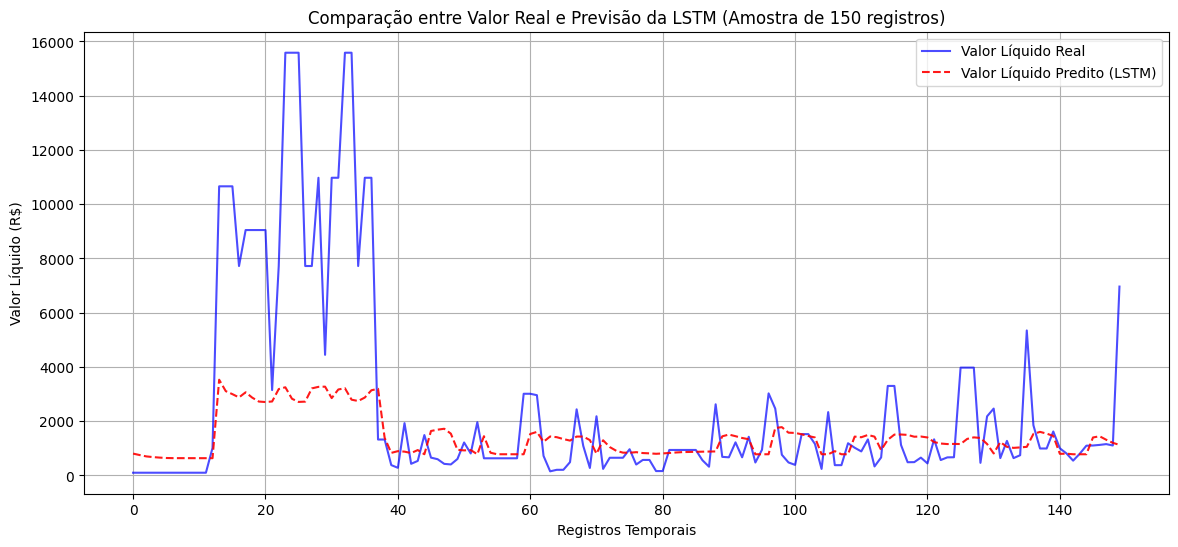

In [32]:
# 4. Plotar gráfico de comparação: Real vs Predito (Amostra dos primeiros 100 pontos para melhor visualização)
plt.figure(figsize=(14, 6))
plt.plot(y_test_real[:150], label='Valor Líquido Real', color='blue', alpha=0.7)
plt.plot(predicoes[:150], label='Valor Líquido Predito (LSTM)', color='red', linestyle='--', alpha=0.9)
plt.title('Comparação entre Valor Real e Previsão da LSTM (Amostra de 150 registros)')
plt.xlabel('Registros Temporais')
plt.ylabel('Valor Líquido (R$)')
plt.legend()
plt.grid(True)
plt.show()

aqui nao de certo o rnn pos nao importava a quantidade de cicolos nao adianta e nao melora a matris de comfusao nem a acuracia



In [33]:
#tentar trocar de algoritimo de procesamento
#teste SVM



In [34]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Definindo as variáveis a partir dos conjuntos 'treino' e 'teste'
X_train = treino.drop(columns=['Valor líquido'])
y_train = treino['Valor líquido']
X_test = teste.drop(columns=['Valor líquido'])
y_test = teste['Valor líquido']

# 1. Definir o limiar (mediana) com os dados de treino para evitar vazamento de dados
limiar = y_train.median()
print(f"Limiar definido (mediana do treino): R$ {limiar:.2f}\n")

# 2. Criar as classes binárias (0 para Baixo, 1 para Alto)
y_train_class = (y_train > limiar).astype(int)
y_test_class = (y_test > limiar).astype(int)

# 3. Treinar o modelo SVM (utilizando amostragem para otimizar o tempo no Colab)
np.random.seed(42)
amostra_indices = np.random.choice(len(X_train_scaled), size=10000, replace=False)

X_train_amostra = X_train_scaled[amostra_indices]
y_train_amostra = y_train_class.iloc[amostra_indices]

print("Treinando o classificador SVM...")
svm_model = SVC(kernel='rbf', C=1.0, random_state=42)
svm_model.fit(X_train_amostra, y_train_amostra)
print("Modelo SVM treinado com sucesso!")

Limiar definido (mediana do treino): R$ 580.98

Treinando o classificador SVM...
Modelo SVM treinado com sucesso!


In [35]:
# 4. Predição no conjunto de teste
y_pred = svm_model.predict(X_test_scaled)

# 5. Calculando as métricas de classificação pedidas
acuracia = accuracy_score(y_test_class, y_pred)
f1 = f1_score(y_test_class, y_pred)
matriz_conf = confusion_matrix(y_test_class, y_pred)

print("=== Métricas de Avaliação - SVM Classificação ===")
print(f"Acurácia: {acuracia:.4f} ({acuracia * 100:.2f}%)")
print(f"F1-Score: {f1:.4f}")
print("\nRelatório Geral de Classificação:")
print(classification_report(y_test_class, y_pred, target_names=['Frete Baixo', 'Frete Alto']))

=== Métricas de Avaliação - SVM Classificação ===
Acurácia: 0.5172 (51.72%)
F1-Score: 0.6818

Relatório Geral de Classificação:
              precision    recall  f1-score   support

 Frete Baixo       0.00      0.00      0.00      8865
  Frete Alto       0.52      1.00      0.68      9497

    accuracy                           0.52     18362
   macro avg       0.26      0.50      0.34     18362
weighted avg       0.27      0.52      0.35     18362



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


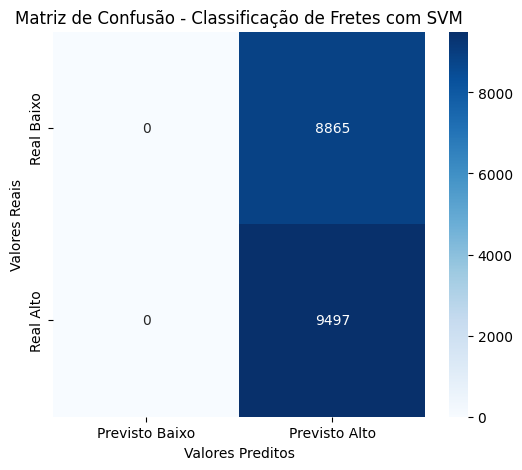

In [36]:
# 6. Plotando a Matriz de Confusão visualmente
plt.figure(figsize=(6, 5))
sns.heatmap(matriz_conf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Previsto Baixo', 'Previsto Alto'],
            yticklabels=['Real Baixo', 'Real Alto'])
plt.title('Matriz de Confusão - Classificação de Fretes com SVM')
plt.ylabel('Valores Reais')
plt.xlabel('Valores Preditos')
plt.show()

In [37]:
#tentar em outo albgoritimo para melhora
#LightGBM

In [38]:
import lightgbm as lgb
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Instanciando e treinando o modelo LightGBM usando todo o conjunto de treino escalonado
print("Treinando o classificador LightGBM...")
lgb_model = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    verbose=-1
)

# Treinando com todo o X_train_scaled (sem necessidade de amostragem lenta)
lgb_model.fit(X_train_scaled, y_train_class)
print("Modelo LightGBM treinado com sucesso!")

Treinando o classificador LightGBM...
Modelo LightGBM treinado com sucesso!


In [39]:
# 2. Realizando as predições no conjunto de teste
y_pred_lgb = lgb_model.predict(X_test_scaled)

# 3. Calculando métricas de classificação
acuracia_lgb = accuracy_score(y_test_class, y_pred_lgb)
f1_lgb = f1_score(y_test_class, y_pred_lgb)
matriz_conf_lgb = confusion_matrix(y_test_class, y_pred_lgb)

print("=== Métricas de Avaliação - LightGBM Classificação ===")
print(f"Acurácia: {acuracia_lgb:.4f} ({acuracia_lgb * 100:.2f}%)")
print(f"F1-Score: {f1_lgb:.4f}")
print("\nRelatório Geral de Classificação:")
print(classification_report(y_test_class, y_pred_lgb, target_names=['Frete Baixo', 'Frete Alto']))

=== Métricas de Avaliação - LightGBM Classificação ===
Acurácia: 0.7628 (76.28%)
F1-Score: 0.7689

Relatório Geral de Classificação:
              precision    recall  f1-score   support

 Frete Baixo       0.75      0.76      0.76      8865
  Frete Alto       0.77      0.76      0.77      9497

    accuracy                           0.76     18362
   macro avg       0.76      0.76      0.76     18362
weighted avg       0.76      0.76      0.76     18362



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


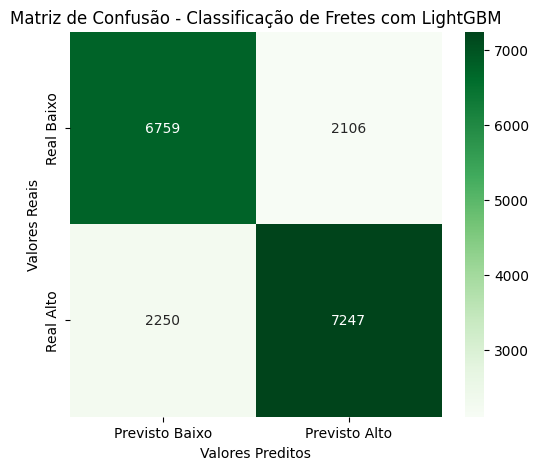

In [40]:
# 4. Plotando a nova Matriz de Confusão para o LightGBM
plt.figure(figsize=(6, 5))
sns.heatmap(matriz_conf_lgb, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Previsto Baixo', 'Previsto Alto'],
            yticklabels=['Real Baixo', 'Real Alto'])
plt.title('Matriz de Confusão - Classificação de Fretes com LightGBM')
plt.ylabel('Valores Reais')
plt.xlabel('Valores Preditos')
plt.show()

In [41]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Instanciando e treinando o modelo XGBoost
print("Treinando o classificador XGBoost...")
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric='logloss'
)

# Treinando com todo o X_train_scaled
xgb_model.fit(X_train_scaled, y_train_class)
print("Modelo XGBoost treinado com sucesso!")

Treinando o classificador XGBoost...
Modelo XGBoost treinado com sucesso!


In [42]:
# 2. Realizando as predições no conjunto de teste
y_pred_xgb = xgb_model.predict(X_test_scaled)

# 3. Calculando métricas de classificação para o XGBoost
acuracia_xgb = accuracy_score(y_test_class, y_pred_xgb)
f1_xgb = f1_score(y_test_class, y_pred_xgb)
matriz_conf_xgb = confusion_matrix(y_test_class, y_pred_xgb)

print("=== Métricas de Avaliação - XGBoost Classificação ===")
print(f"Acurácia: {acuracia_xgb:.4f} ({acuracia_xgb * 100:.2f}%)")
print(f"F1-Score: {f1_xgb:.4f}")
print("\nRelatório Geral de Classificação:")
print(classification_report(y_test_class, y_pred_xgb, target_names=['Frete Baixo', 'Frete Alto']))

=== Métricas de Avaliação - XGBoost Classificação ===
Acurácia: 0.7685 (76.85%)
F1-Score: 0.7723

Relatório Geral de Classificação:
              precision    recall  f1-score   support

 Frete Baixo       0.75      0.78      0.76      8865
  Frete Alto       0.79      0.76      0.77      9497

    accuracy                           0.77     18362
   macro avg       0.77      0.77      0.77     18362
weighted avg       0.77      0.77      0.77     18362



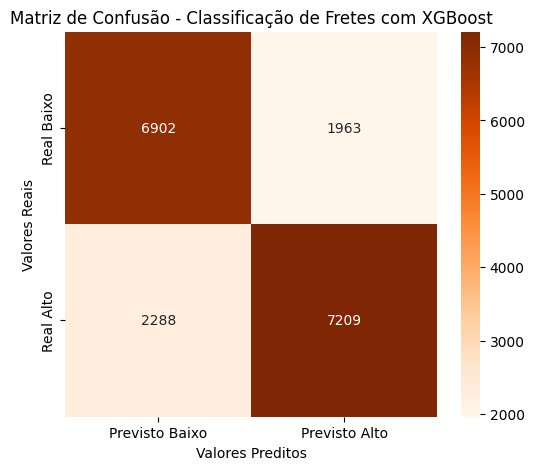

In [43]:
# 4. Plotando a nova Matriz de Confusão para o XGBoost
plt.figure(figsize=(6, 5))
sns.heatmap(matriz_conf_xgb, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Previsto Baixo', 'Previsto Alto'],
            yticklabels=['Real Baixo', 'Real Alto'])
plt.title('Matriz de Confusão - Classificação de Fretes com XGBoost')
plt.ylabel('Valores Reais')
plt.xlabel('Valores Preditos')
plt.show()

In [44]:
!pip install catboost -q

In [45]:
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Instanciando e treinando o modelo CatBoost
print("Treinando o classificador CatBoost...")
cat_model = CatBoostClassifier(
    iterations=150,
    learning_rate=0.1,
    depth=6,
    random_seed=42,
    verbose=0
)

# Treinando com todo o X_train_scaled
cat_model.fit(X_train_scaled, y_train_class)
print("Modelo CatBoost treinado com sucesso!")

Treinando o classificador CatBoost...
Modelo CatBoost treinado com sucesso!


In [46]:
# 2. Realizando as predições no conjunto de teste
y_pred_cat = cat_model.predict(X_test_scaled)

# 3. Calculando as métricas para o CatBoost
acuracia_cat = accuracy_score(y_test_class, y_pred_cat)
f1_cat = f1_score(y_test_class, y_pred_cat)
matriz_conf_cat = confusion_matrix(y_test_class, y_pred_cat)

print("=== Métricas de Avaliação - CatBoost Classificação ===")
print(f"Acurácia: {acuracia_cat:.4f} ({acuracia_cat * 100:.2f}%)")
print(f"F1-Score: {f1_cat:.4f}")
print("\nRelatório Geral de Classificação:")
print(classification_report(y_test_class, y_pred_cat, target_names=['Frete Baixo', 'Frete Alto']))

=== Métricas de Avaliação - CatBoost Classificação ===
Acurácia: 0.7733 (77.33%)
F1-Score: 0.7748

Relatório Geral de Classificação:
              precision    recall  f1-score   support

 Frete Baixo       0.75      0.79      0.77      8865
  Frete Alto       0.80      0.75      0.77      9497

    accuracy                           0.77     18362
   macro avg       0.77      0.77      0.77     18362
weighted avg       0.77      0.77      0.77     18362



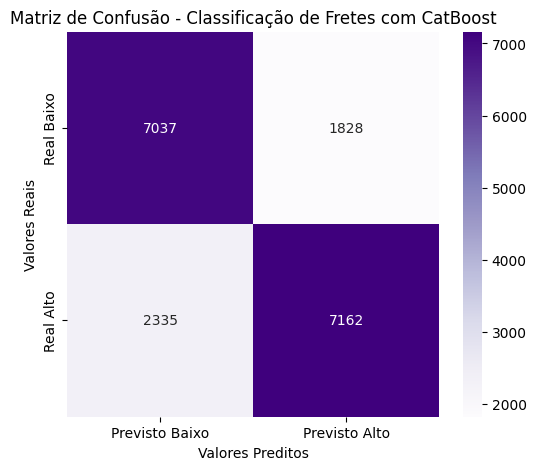

In [47]:
# 4. Plotando a matriz de confusão para o CatBoost
plt.figure(figsize=(6, 5))
sns.heatmap(matriz_conf_cat, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Previsto Baixo', 'Previsto Alto'],
            yticklabels=['Real Baixo', 'Real Alto'])
plt.title('Matriz de Confusão - Classificação de Fretes com CatBoost')
plt.ylabel('Valores Reais')
plt.xlabel('Valores Preditos')
plt.show()

Aproveitando os dados já carregados e tratados na memória...
Treinando o classificador CatBoost...
Modelo treinado com sucesso!

=== Métricas de Avaliação - CatBoost Classificação ===
Acurácia do Modelo: 0.7733 (77.33%)
F1-Score Geral: 0.7748

Relatório de Desempenho Detalhado:
              precision    recall  f1-score   support

 Frete Baixo       0.75      0.79      0.77      8865
  Frete Alto       0.80      0.75      0.77      9497

    accuracy                           0.77     18362
   macro avg       0.77      0.77      0.77     18362
weighted avg       0.77      0.77      0.77     18362



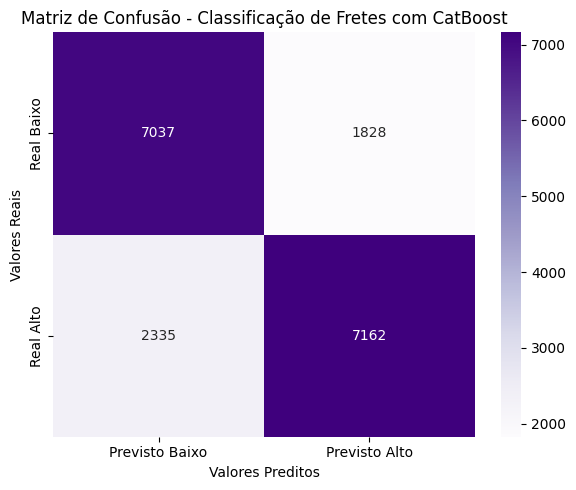

In [49]:
# 1. Instalação de Dependências e Importação de Bibliotecas
!pip install catboost -q

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

# 2. Uso dos dados já preparados e consolidados na memória do Colab
print("Aproveitando os dados já carregados e tratados na memória...")
# X_train, y_train, X_test e y_test já foram definidos nas células anteriores

# 3. Pré-processamento: Criação do Alvo Binário (Mediana) e Escalonamento
limiar = y_train.median()
y_train_class = (y_train > limiar).astype(int)
y_test_class = (y_test > limiar).astype(int)

scaler_X = MinMaxScaler(feature_range=(0, 1))
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# 4. Treinamento do Modelo CatBoost Classifier
print("Treinando o classificador CatBoost...")
cat_model = CatBoostClassifier(
    iterations=150,
    learning_rate=0.1,
    depth=6,
    random_seed=42,
    verbose=0
)
cat_model.fit(X_train_scaled, y_train_class)
print("Modelo treinado com sucesso!")

# 5. Predição e Avaliação de Desempenho
y_pred_cat = cat_model.predict(X_test_scaled)

acuracia_cat = accuracy_score(y_test_class, y_pred_cat)
f1_cat = f1_score(y_test_class, y_pred_cat)
matriz_conf_cat = confusion_matrix(y_test_class, y_pred_cat)

print("\n=== Métricas de Avaliação - CatBoost Classificação ===")
print(f"Acurácia do Modelo: {acuracia_cat:.4f} ({acuracia_cat * 100:.2f}%)")
print(f"F1-Score Geral: {f1_cat:.4f}")
print("\nRelatório de Desempenho Detalhado:")
print(classification_report(y_test_class, y_pred_cat, target_names=['Frete Baixo', 'Frete Alto']))

# 6. Geração e Plotagem da Matriz de Confusão
plt.figure(figsize=(6, 5))
sns.heatmap(matriz_conf_cat, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Previsto Baixo', 'Previsto Alto'],
            yticklabels=['Real Baixo', 'Real Alto'])
plt.title('Matriz de Confusão - Classificação de Fretes com CatBoost')
plt.ylabel('Valores Reais')
plt.xlabel('Valores Preditos')
plt.tight_layout()
plt.show()